# Assignment #4 | Anggota 3: Label Quality dengan Cleanlab (Instruksi 4 & 5)

Notebook ini menjawab dua pertanyaan: *label mana yang patut dicurigai, dan apakah memperbaikinya membuat model lebih baik?*

Cleanlab dijalankan pada probabilitas *out-of-fold* baseline (D0). Hasilnya hanya daftar kandidat, karena perbedaan antara prediksi model dan label asli bukan bukti bahwa label salah. Setiap kandidat lalu direview dengan bukti tambahan dan diberi keputusan **Keep / Correct / Remove / Unresolved**. Keputusan itu dipakai pada eksperimen **D0–D3** dengan model, fitur, dan fold yang sama.

**Hasil singkat:** dari 26 observasi yang ditandai, 2 label dikoreksi, 0 dihapus, 6 tidak terselesaikan, dan 18 dipertahankan. Koreksi menaikkan macro F1 hanya +0,0045 (di bawah noise antar-fold). **D1 (SMOTE tanpa koreksi label) tetap yang tertinggi**, baik pada label validasi asli maupun terkoreksi.

| Bagian | Isi | Instruksi |
|---|---|---|
| A | Kerangka bersama (salinan persis dari notebook Anggota 1) | — |
| B | Cleanlab pada OOF baseline dan stabilitas daftarnya | 4 |
| C | Review kandidat: bukti tambahan, aturan keputusan, tabel Keep/Correct/Remove/Unresolved | 4 |
| D | Eksperimen D0–D3: mean ± std CV, selisih berpasangan, label validasi asli vs terkoreksi | 5 |
| E | Rekomendasi dan konfigurasi untuk anggota lain | 5, 8 |
| F | Bahan diskusi laporan | 9 (bagian Anggota 3) |

**Aturan yang dijaga:** test set tidak disentuh di notebook ini, label tidak diubah tanpa bukti yang ditulis eksplisit, dan semua modifikasi hanya berlaku pada bagian train tiap fold.

# BAGIAN A | Kerangka bersama

Sel **A1–A8** adalah **salinan persis** dari notebook Anggota 1 (setup, load data, split terkunci, fold CV terkunci, preprocessing E0/E5, metrik, model ensemble, `evaluate_cv`), sehingga split, fold, model, dan metrik identik dengan anggota lain. Penjelasan tiap sel ada di `Assignment4_Anggota1.ipynb`.

## A1. Setup & konfigurasi

In [1]:
import os, json, time, warnings
warnings.filterwarnings("ignore")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")

import numpy as np
import pandas as pd
import sklearn
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             balanced_accuracy_score, matthews_corrcoef, roc_auc_score,
                             average_precision_score, confusion_matrix)

# ---------------- KONFIGURASI (dikunci bersama di ./artifacts/) ----------------
PATH       = "./dataset/heart_disease_cleveland.csv"
ART_DIR    = "./artifacts"
SEED       = 42
TARGET     = "num"
N_SPLITS   = 5
N_REPEATS  = 3
TEST_SIZE  = 0.2
RF_PARAMS  = {"n_estimators": 194, "max_depth": 43}                      # dari Assignment #3
CNN_PARAMS = {"filters": 34, "kernel_size": 2, "dense_units": 50,
              "learning_rate": 0.001, "epochs": 50, "batch_size": 32}     # dari Assignment #3
os.makedirs(ART_DIR, exist_ok=True)

print("sklearn", sklearn.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)
try:
    import tensorflow as tf; print("tensorflow", tf.__version__)
    import logging; logging.getLogger("tensorflow").setLevel(logging.ERROR)
except Exception as e:
    print("TensorFlow belum terpasang:", e)

sklearn 1.9.0 | numpy 2.5.0 | pandas 3.0.3


I0000 00:00:1793500238.347512  459359 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1793500239.258482  459359 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


tensorflow 2.21.0


## A2. Load data + pemeriksaan integritas

In [2]:
df = pd.read_csv(PATH).rename(columns={"target": TARGET})
df.insert(0, "row_id", np.arange(len(df)))

print("Bentuk:", df.shape)
print("Missing per kolom (data penuh):", df.isna().sum()[df.isna().sum() > 0].to_dict())
print("Duplikat persis:", df.drop(columns="row_id").duplicated().sum())
print("Distribusi target (data penuh):", df[TARGET].value_counts().sort_index().to_dict())
assert set(df[TARGET].unique()) == {0, 1}, "target harus biner 0/1"
df.head(3)

Bentuk: (303, 15)
Missing per kolom (data penuh): {'ca': 4, 'thal': 2}
Duplikat persis: 0
Distribusi target (data penuh): {0: 164, 1: 139}


,row_id,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1


## A3. Split train/test (dibaca dari `split.json`)

In [3]:
def get_split(df):
    p = f"{ART_DIR}/split.json"
    if os.path.exists(p):
        ids = json.load(open(p))
    else:
        tr, te = train_test_split(df, test_size=TEST_SIZE, random_state=SEED, stratify=df[TARGET])
        ids = {"train": sorted(tr.row_id.tolist()), "test": sorted(te.row_id.tolist())}
        json.dump(ids, open(p, "w"))
    train_df = df[df.row_id.isin(ids["train"])].reset_index(drop=True)
    test_df  = df[df.row_id.isin(ids["test"])].reset_index(drop=True)
    assert not set(train_df.row_id) & set(test_df.row_id), "train/test overlap!"
    return train_df, test_df

train_df, test_df = get_split(df)
print("Train:", train_df.shape, "| Test:", test_df.shape)
print("Kelas train:", train_df[TARGET].value_counts().sort_index().to_dict())

Train: (242, 15) | Test: (61, 15)
Kelas train: {0: 131, 1: 111}


## A4. Fold CV (dibaca dari `cv_splits.json`)

In [4]:
def get_cv_splits(train_df):
    p = f"{ART_DIR}/cv_splits.json"
    if os.path.exists(p):
        return [(np.array(a), np.array(b), r) for a, b, r in json.load(open(p))]
    rskf = RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=SEED)
    out = []
    for i, (a, b) in enumerate(rskf.split(train_df, train_df[TARGET])):
        out.append((train_df.row_id.values[a].tolist(), train_df.row_id.values[b].tolist(), i // N_SPLITS))
    json.dump(out, open(p, "w"))
    return [(np.array(a), np.array(b), r) for a, b, r in out]

cv = get_cv_splits(train_df)
print("Jumlah fold:", len(cv), "| ukuran validasi fold-0:", len(cv[0][1]))

Jumlah fold: 15 | ukuran validasi fold-0: 49


## A5. Preprocessing E0 dan E5

In [5]:
# Konstanta kolom (dari notebook Assignment #3)
continuous_cols   = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
categorical_cols  = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']
NOMINAL_COLS      = ['cp', 'restecg', 'thal']
ORDINAL_COLS      = ['ca', 'slope']
BINARY_COLS       = ['sex', 'fbs', 'exang']
LOG_COLS          = ['chol', 'oldpeak']
MISSING_FLAG_COLS = ['ca', 'thal']
ENGINEERED_COLS   = ['hr_reserve', 'st_severity']


class IQRClipper(BaseEstimator, TransformerMixin):
    """Winsorize dengan batas IQR (baris TIDAK dihapus). Batas dihitung dari data fit (train saja)."""
    def __init__(self, k=1.5):
        self.k = k
    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        q1, q3 = np.nanpercentile(X, 25, axis=0), np.nanpercentile(X, 75, axis=0)
        iqr = q3 - q1
        self.lo_, self.hi_ = q1 - self.k * iqr, q3 + self.k * iqr
        return self
    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lo_, self.hi_)


def _base_impute(tr, ev):
    """Imputasi median (kontinu) / modus (kategorikal). Fit HANYA di train, transform ke train & eval."""
    num_imp = SimpleImputer(strategy='median').fit(tr[continuous_cols])
    cat_imp = SimpleImputer(strategy='most_frequent').fit(tr[categorical_cols])
    for d in (tr, ev):
        d[continuous_cols] = num_imp.transform(d[continuous_cols])
        d[categorical_cols] = cat_imp.transform(d[categorical_cols])


def preprocess_E0(tr_df, ev_df):
    tr, ev = tr_df.copy(), ev_df.copy()
    y_tr = tr.pop(TARGET).to_numpy(dtype=int)

    _base_impute(tr, ev)
    for c in categorical_cols:
        tr[c] = tr[c].round().astype(int)
        ev[c] = ev[c].round().astype(int)

    q1, q3 = tr[continuous_cols].quantile(0.25), tr[continuous_cols].quantile(0.75)
    lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    mask = ((tr[continuous_cols] >= lo) & (tr[continuous_cols] <= hi)).all(axis=1)
    y_tr = y_tr[mask.to_numpy()]
    tr = tr.loc[mask].reset_index(drop=True)

    feature_names = continuous_cols + categorical_cols
    scaler = MinMaxScaler().fit(tr[feature_names])
    X_train = scaler.transform(tr[feature_names])
    X_eval = scaler.transform(ev[feature_names])
    return X_train, y_tr, X_eval, feature_names


def preprocess_E5(tr_df, ev_df):
    tr, ev = tr_df.copy(), ev_df.copy()
    y_tr = tr.pop(TARGET).to_numpy(dtype=int)

    missing_flag_cols = [f'{c}_missing' for c in MISSING_FLAG_COLS]
    for d in (tr, ev):
        for c in MISSING_FLAG_COLS:
            d[f'{c}_missing'] = d[c].isna().astype(int)

    _base_impute(tr, ev)
    for c in NOMINAL_COLS + BINARY_COLS + ORDINAL_COLS:
        tr[c] = tr[c].round().astype(int)
        ev[c] = ev[c].round().astype(int)

    for d in (tr, ev):
        d['hr_reserve'] = d['thalach'] - (220 - d['age'])
        d['st_severity'] = d['oldpeak'] * d['slope']

    for c in LOG_COLS:
        tr[c] = np.log1p(tr[c])
        ev[c] = np.log1p(ev[c])

    clip_cols = continuous_cols + ENGINEERED_COLS
    clipper = IQRClipper().fit(tr[clip_cols])
    tr[clip_cols] = clipper.transform(tr[clip_cols])
    ev[clip_cols] = clipper.transform(ev[clip_cols])

    ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False).fit(tr[NOMINAL_COLS].astype(str))
    nom_names = list(ohe.get_feature_names_out(NOMINAL_COLS))
    scale_cols = continuous_cols + ENGINEERED_COLS + ORDINAL_COLS
    scaler = MinMaxScaler().fit(tr[scale_cols])

    def assemble(d):
        num = pd.DataFrame(scaler.transform(d[scale_cols]), columns=scale_cols, index=d.index)
        nom = pd.DataFrame(ohe.transform(d[NOMINAL_COLS].astype(str)), columns=nom_names, index=d.index)
        rest = d[BINARY_COLS + missing_flag_cols]
        return pd.concat([num, rest, nom], axis=1)

    feature_names = scale_cols + BINARY_COLS + missing_flag_cols + nom_names
    return (assemble(tr)[feature_names].to_numpy(dtype=float), y_tr,
            assemble(ev)[feature_names].to_numpy(dtype=float), feature_names)


PREPROCESS = {'E0': preprocess_E0, 'E5': preprocess_E5}
BASELINE_CODE = "E5"   # Dikunci oleh Anggota 1 (sel B2)

## A6. Metrik evaluasi

In [6]:
def compute_metrics(y_true, y_pred, y_prob):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        "accuracy":     accuracy_score(y_true, y_pred),
        "macro_f1":     f1_score(y_true, y_pred, average="macro", zero_division=0),
        "balanced_acc": balanced_accuracy_score(y_true, y_pred),
        "mcc":          matthews_corrcoef(y_true, y_pred),
        "precision":    precision_score(y_true, y_pred, zero_division=0),
        "recall":       recall_score(y_true, y_pred, zero_division=0),
        "f1_pos":       f1_score(y_true, y_pred, zero_division=0),
        "specificity":  tn / (tn + fp) if (tn + fp) else np.nan,
        "roc_auc":      roc_auc_score(y_true, y_prob),
        "pr_auc":       average_precision_score(y_true, y_prob),
    }
METRIC_COLS = ["accuracy", "macro_f1", "balanced_acc", "mcc", "roc_auc", "pr_auc"]
ALL_METRIC_COLS = ["accuracy", "macro_f1", "balanced_acc", "mcc", "precision", "recall", "f1_pos", "specificity", "roc_auc", "pr_auc"]

## A7. Model ensemble RF + CNN

In [7]:
def rf_fit_predict(X_tr, y_tr, X_ev, sample_weight=None, **_):
    rf = RandomForestClassifier(random_state=SEED, **RF_PARAMS).fit(X_tr, y_tr, sample_weight=sample_weight)
    return {"prob": rf.predict_proba(X_ev)[:, 1], "model": rf}


def make_ensemble_fit_predict(rf_params=None, cnn_params=None, keep_models=False):
    rf_params, cnn_params = rf_params or RF_PARAMS, cnn_params or CNN_PARAMS

    def fit_predict(X_tr, y_tr, X_ev, sample_weight=None, **_):
        import tensorflow as tf
        from tensorflow.keras.models import Sequential
        from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense
        from tensorflow.keras.optimizers import Adam
        rf = RandomForestClassifier(random_state=SEED, **rf_params).fit(X_tr, y_tr, sample_weight=sample_weight)
        p_rf = rf.predict_proba(X_ev)[:, 1]
        tf.keras.utils.set_random_seed(SEED)
        m = Sequential([Conv1D(cnn_params["filters"], cnn_params["kernel_size"], activation="relu",
                               input_shape=(X_tr.shape[1], 1)),
                        MaxPooling1D(2), Flatten(),
                        Dense(cnn_params["dense_units"], activation="relu"),
                        Dense(1, activation="sigmoid")])
        m.compile(optimizer=Adam(cnn_params["learning_rate"]), loss="binary_crossentropy")
        m.fit(X_tr[..., None], y_tr, sample_weight=sample_weight, epochs=cnn_params["epochs"],
              batch_size=cnn_params["batch_size"], validation_split=0.2, verbose=0)
        p_cnn = m.predict(X_ev[..., None], verbose=0).ravel()
        votes = (p_rf >= .5).astype(int) + (p_cnn >= .5).astype(int)
        avg   = .5 * p_rf + .5 * p_cnn
        pred  = np.where(votes == 2, 1, np.where(votes == 0, 0, (avg >= .5).astype(int)))
        res = {"prob": avg, "pred": pred, "rf_prob": p_rf, "cnn_prob": p_cnn, "model": rf}
        if keep_models:
            res["cnn_model"] = m
            res["predict_fn"] = lambda X: .5 * rf.predict_proba(np.asarray(X, float))[:, 1] + \
                                          .5 * m.predict(np.asarray(X, float)[..., None], verbose=0).ravel()
        else:
            tf.keras.backend.clear_session()
        return res
    return fit_predict

## A8. `evaluate_cv` dan fungsi helper

In [8]:
def apply_train_modifications(tr, label_overrides=None, drop_ids=None):
    tr = tr.copy()
    if label_overrides:
        m = tr.row_id.isin(label_overrides)
        tr.loc[m, TARGET] = tr.loc[m, "row_id"].map(label_overrides).astype(int)
    if drop_ids:
        tr = tr[~tr.row_id.isin(set(drop_ids))]
    return tr.reset_index(drop=True)


def evaluate_cv(exp_code, train_df, preprocess_fn, fit_predict=None,
                label_overrides=None, drop_ids=None, resampler=None, sample_weight_fn=None,
                eval_on_corrected=False, results_csv=f"{ART_DIR}/cv_results.csv", verbose=True):
    fit_predict = fit_predict or make_ensemble_fit_predict()
    rows, oof = [], []
    by_id = train_df.set_index("row_id", drop=False)
    for k, (tr_ids, va_ids, rep) in enumerate(get_cv_splits(train_df)):
        tr = apply_train_modifications(by_id.loc[tr_ids].reset_index(drop=True), label_overrides, drop_ids)
        va = by_id.loc[va_ids].reset_index(drop=True)
        X_tr, y_tr, X_ev, feats = preprocess_fn(tr.drop(columns=["row_id"]),
                                                va.drop(columns=["row_id", TARGET]))
        X_tr, X_ev, y_tr = np.asarray(X_tr, float), np.asarray(X_ev, float), np.asarray(y_tr, int)
        assert len(X_ev) == len(va), "preprocessing tidak boleh membuang baris validasi"
        sw = sample_weight_fn(y_tr) if sample_weight_fn else None
        if resampler:
            X_tr, y_tr = resampler(X_tr, y_tr); sw = None
        out  = fit_predict(X_tr, y_tr, X_ev, sample_weight=sw)
        prob = out["prob"]
        pred = out.get("pred", (prob >= .5).astype(int))
        if eval_on_corrected and label_overrides:
            va = apply_train_modifications(va, label_overrides, None)
        y_va = va[TARGET].to_numpy(int)
        rows.append({"exp": exp_code, "fold": k, "repeat": rep, "n_train": len(y_tr),
                     **compute_metrics(y_va, pred, prob)})
        oof.append(pd.DataFrame({"row_id": va.row_id, "repeat": rep, "prob": prob,
                                 "rf_prob": out["rf_prob"], "cnn_prob": out["cnn_prob"], "y": y_va}))
    fold_df = pd.DataFrame(rows)
    oof_df = pd.concat(oof).groupby("row_id").agg(
        prob=("prob", "mean"), rf_prob=("rf_prob", "mean"),
        cnn_prob=("cnn_prob", "mean"), y=("y", "first")
    ).reset_index()

    old = pd.read_csv(results_csv) if os.path.exists(results_csv) else pd.DataFrame()
    pd.concat([old[old.exp != exp_code] if len(old) else old, fold_df]).to_csv(results_csv, index=False)
    if verbose:
        print(f"[{exp_code}] {len(fold_df)} fold  |  mean ± std")
        s = fold_df[METRIC_COLS].agg(["mean", "std"]).T
        print("\n".join(f"  {m:13s} {r['mean']:.4f} ± {r['std']:.4f}" for m, r in s.iterrows()))
    return fold_df, oof_df


def summarize(results_csv=f"{ART_DIR}/cv_results.csv", metric="macro_f1"):
    r = pd.read_csv(results_csv)
    g = r.groupby("exp")[METRIC_COLS].agg(["mean", "std"])
    return g.sort_values((metric, "mean"), ascending=False).round(4)


def paired_delta(baseline, other, metric="macro_f1", results_csv=f"{ART_DIR}/cv_results.csv"):
    r = pd.read_csv(results_csv).pivot(index="fold", columns="exp", values=metric)
    d = r[other] - r[baseline]
    return {"delta_mean": round(d.mean(), 4), "delta_std": round(d.std(), 4),
            "menang": int((d > 0).sum()), "kalah": int((d < 0).sum()), "seri": int((d == 0).sum())}

## A9. Library tambahan & direktori artefak Anggota 3

Hanya perlu `cleanlab` dan `imbalanced-learn` (SMOTE untuk D1 dan D3) di luar kerangka bersama:
```
pip install cleanlab imbalanced-learn
```
`FORCE_RERUN = False` memuat hasil yang sudah tersimpan di `./artifacts/`. Ubah ke `True` untuk melatih ulang semuanya (±15 menit di CPU).

In [9]:
import cleanlab
from cleanlab.filter import find_label_issues
from cleanlab.rank import get_label_quality_scores
from cleanlab.count import estimate_joint
import imblearn
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from scipy.stats import ttest_rel, wilcoxon
import matplotlib.pyplot as plt

OUT_DIR  = f"{ART_DIR}/anggota3"
DIAG_CSV = f"{OUT_DIR}/cv_diagnostics.csv"
FORCE_RERUN = False
os.makedirs(OUT_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_rows", 100, "display.max_columns", 40, "display.width", 220)
print("cleanlab:", cleanlab.__version__, "| imbalanced-learn:", imblearn.__version__, "| Direktori output:", OUT_DIR)

cleanlab: 2.9.0 | imbalanced-learn: 0.14.2 | Direktori output: ./artifacts/anggota3


# BAGIAN B | Cleanlab pada prediksi out-of-fold (Instruksi 4)

## B1. Menjalankan Cleanlab

Masukannya `artifacts/oof_baseline.csv`: probabilitas ensemble RF + CNN D0, rata-rata 3 repeat. Probabilitas harus *out-of-fold*, karena model yang pernah melihat sebuah baris cenderung menghafal labelnya, sehingga label yang salah tidak akan terdeteksi.

| Istilah | Arti |
|---|---|
| `kualitas` | skor *self-confidence*: probabilitas model untuk label yang tercatat. Makin kecil, makin tidak cocok |
| `flag` | hasil `find_label_issues` (`prune_by_noise_rate`, bawaan Cleanlab) |

In [10]:
oof_d0 = pd.read_csv(f"{ART_DIR}/oof_baseline.csv").sort_values("row_id").reset_index(drop=True)

# OOF harus mencakup tepat seluruh data train, dengan label asli, dan tidak menyentuh test set
assert set(oof_d0.row_id) == set(train_df.row_id), "OOF harus tepat berisi baris train"
assert (oof_d0.y.values == train_df.sort_values("row_id")[TARGET].values).all(), "label OOF berbeda dari label train"
assert not set(oof_d0.row_id) & set(test_df.row_id), "test set tidak boleh ikut"

P_d0 = np.c_[1 - oof_d0.prob, oof_d0.prob]
y_d0 = oof_d0.y.to_numpy(int)

oof_d0["kualitas"] = get_label_quality_scores(y_d0, P_d0, method="self_confidence")
oof_d0["flag"]     = find_label_issues(y_d0, P_d0, filter_by="prune_by_noise_rate")

print("Observasi train:", len(oof_d0))
print("Ditandai Cleanlab:", int(oof_d0.flag.sum()), f"({oof_d0.flag.mean()*100:.1f}% dari train)")
print("  label 1, diprediksi sehat:", int((oof_d0.flag & (oof_d0.y == 1)).sum()))
print("  label 0, diprediksi sakit:", int((oof_d0.flag & (oof_d0.y == 0)).sum()))
print("Semua kesalahan prediksi OOF:", int(((oof_d0.prob >= .5).astype(int) != oof_d0.y).sum()))

joint = pd.DataFrame(estimate_joint(y_d0, P_d0), index=["label tercatat 0", "label tercatat 1"],
                     columns=["label sebenarnya 0", "label sebenarnya 1"]).round(3)
display(joint)

filter_cmp = {m: int(find_label_issues(y_d0, P_d0, filter_by=m).sum())
              for m in ["prune_by_noise_rate", "prune_by_class", "both", "confident_learning", "predicted_neq_given"]}
print("Jumlah observasi per metode filter:", filter_cmp)

Observasi train: 242
Ditandai Cleanlab: 26 (10.7% dari train)
  label 1, diprediksi sehat: 17
  label 0, diprediksi sakit: 9
Semua kesalahan prediksi OOF: 46


,label sebenarnya 0,label sebenarnya 1
label tercatat 0,0.504,0.037
label tercatat 1,0.070,0.388


Jumlah observasi per metode filter: {'prune_by_noise_rate': 26, 'prune_by_class': 26, 'both': 26, 'confident_learning': 18, 'predicted_neq_given': 46}


**Cara membaca:** Cleanlab menandai **26 dari 242 observasi train (10,7%)**: 17 berlabel sakit tetapi diprediksi sehat, dan 9 sebaliknya. Dari matriks gabungan, label tercatat 1 yang "seharusnya" 0 (7,0%) hampir dua kali lipat kebalikannya (3,7%). Ini arah yang sama dengan asimetri FN vs FP yang ditemukan Anggota 2.

Angka 10,7% **bukan** estimasi label salah. Cleanlab tidak bisa membedakan label yang salah dari pasien yang memang sulit diprediksi dengan 13 fitur ini. Daftarnya juga bagian dari 46 kesalahan prediksi OOF, jadi tiap kandidat tetap harus diperiksa satu per satu.

Metode filter yang lain memberi 26 (`prune_by_class`, `both`) dan 18 (`confident_learning`). Yang dipakai adalah 26 agar review tidak melewatkan kandidat; keputusan akhirnya tetap ditentukan di Bagian C.

## B2. Apakah daftarnya stabil? Cleanlab per repeat

Setiap repeat CV adalah pembagian fold yang berbeda. Kalau sebuah observasi hanya ditandai pada satu pembagian, penandaannya lebih mungkin kebetulan. Untuk itu baseline dijalankan ulang dengan pembungkus kecil yang mencatat probabilitas per fold. `evaluate_cv` tidak diubah, dan hasilnya disimpan terpisah sebagai `D0_rerun` di `cv_diagnostics.csv`.

In [11]:
def recording(fit_predict, store):
    """Membungkus fit_predict agar keluaran tiap fold tersimpan, tanpa mengubah evaluate_cv."""
    def wrapped(X_tr, y_tr, X_ev, sample_weight=None, **kw):
        out = fit_predict(X_tr, y_tr, X_ev, sample_weight=sample_weight, **kw)
        store.append({k: out[k] for k in ("prob", "rf_prob", "cnn_prob")})
        return out
    return wrapped


def run_or_load(exp_code, results_csv, oof_path, **kwargs):
    """Pola yang sama dengan Anggota 2: muat dari artifacts bila ada, latih bila belum."""
    done = pd.read_csv(results_csv) if os.path.exists(results_csv) else pd.DataFrame(columns=["exp"])
    if not FORCE_RERUN and exp_code in set(done.exp) and os.path.exists(oof_path):
        return done[done.exp == exp_code].reset_index(drop=True), pd.read_csv(oof_path)
    t0 = time.time()
    fold_df, oof_df = evaluate_cv(exp_code, train_df, PREPROCESS[BASELINE_CODE], results_csv=results_csv, verbose=False, **kwargs)
    oof_df.to_csv(oof_path, index=False)
    print(f"[{exp_code}] selesai dalam {time.time()-t0:.0f} detik")
    return fold_df, oof_df


perfold_path = f"{OUT_DIR}/oof_d0_perfold.csv"
store = []
fold_d0r, oof_d0r = run_or_load("D0_rerun", DIAG_CSV, f"{OUT_DIR}/oof_d0_rerun.csv",
                                fit_predict=recording(make_ensemble_fit_predict(), store))
if store:
    pd.concat([pd.DataFrame({"row_id": va, "fold": k, "repeat": rep, **store[k]})
               for k, (_, va, rep) in enumerate(cv)]).to_csv(perfold_path, index=False)
perfold = pd.read_csv(perfold_path).merge(oof_d0[["row_id", "y"]], on="row_id")

# Kerangka reproduksi: D0 di mesin ini vs D0 yang dikunci Anggota 1
r_main = pd.read_csv(f"{ART_DIR}/cv_results.csv")
locked = r_main[r_main.exp == BASELINE_CODE].sort_values("fold")
print(f"Macro F1 D0 terkunci (E5): {locked.macro_f1.mean():.4f} | D0_rerun: {fold_d0r.macro_f1.mean():.4f} | "
      f"fold yang identik: {int(np.isclose(locked.macro_f1.values, fold_d0r.sort_values('fold').macro_f1.values).sum())}/15")
print("Korelasi prob OOF terkunci vs rerun:", round(np.corrcoef(oof_d0.prob, oof_d0r.sort_values("row_id").prob)[0, 1], 4))

# Cleanlab dijalankan pada tiap repeat secara terpisah
stab = []
for rep, g in perfold.groupby("repeat"):
    g = g.sort_values("row_id")
    P = np.c_[1 - g.prob, g.prob]
    stab.append(pd.Series(find_label_issues(g.y.to_numpy(int), P, filter_by="prune_by_noise_rate"),
                          index=g.row_id.values, name=f"flag_r{rep}"))
stab = pd.concat(stab, axis=1).astype(int)
oof_d0 = oof_d0.merge(stab.sum(axis=1).rename("flag_n_repeat"), left_on="row_id", right_index=True)

# Pada berapa repeat model salah, dan apakah RF dan CNN sama-sama menentang label
pf = perfold.assign(salah=(perfold.prob >= .5).astype(int) != perfold.y)
oof_d0 = oof_d0.merge(pf.groupby("row_id").salah.sum().rename("salah_n_repeat"), left_on="row_id", right_index=True)
m_rc = oof_d0r[["row_id", "rf_prob", "cnn_prob"]].merge(oof_d0[["row_id", "y"]], on="row_id")
m_rc["rf_cnn_menentang"] = (((m_rc.rf_prob >= .5).astype(int) != m_rc.y) & ((m_rc.cnn_prob >= .5).astype(int) != m_rc.y))
oof_d0 = oof_d0.merge(m_rc[["row_id", "rf_cnn_menentang"]], on="row_id")

print("\nJumlah repeat (dari 3) yang menandai tiap observasi di daftar utama:")
print(oof_d0[oof_d0.flag].flag_n_repeat.value_counts().sort_index().to_dict())

Macro F1 D0 terkunci (E5): 0.8028 | D0_rerun: 0.8028 | fold yang identik: 15/15
Korelasi prob OOF terkunci vs rerun: 1.0



Jumlah repeat (dari 3) yang menandai tiap observasi di daftar utama:
{0: 1, 1: 2, 2: 7, 3: 16}


**Cara membaca:**
- **D0 yang dijalankan ulang identik dengan D0 terkunci** (15 dari 15 fold, korelasi probabilitas 1,0), jadi hasil D1–D3 di notebook ini bisa dibandingkan langsung dengan angka anggota lain.
- Dari 26 observasi, **16 ditandai di ketiga repeat**, 7 di dua repeat, 2 di satu repeat, dan 1 tidak ditandai jika tiap repeat dinilai sendiri. Yang ditandai 3 kali lebih layak direview serius; sisanya lebih dekat ke kebetulan pembagian fold.
- Stabil tidak berarti labelnya salah. Stabilitas hanya menunjukkan bahwa ketidakcocokan itu bukan kebetulan.

# BAGIAN C | Review kandidat (Instruksi 4)

Dataset ini hanya berisi target biner, tanpa rekam medis, jadi tidak ada sumber yang bisa membuktikan sebuah label salah secara langsung. Review memakai tiga jenis bukti tambahan, dengan batasnya masing-masing:

| Bukti | Pertanyaan | Batas |
|---|---|---|
| Model lain (C1) | Apakah model dengan cara kerja berbeda ikut menentang label? | Memakai fitur yang sama, jadi bukan bukti independen |
| Tes objektif (C2) | Apakah hasil tes pasien bertentangan dengan label? | Tes bisa positif palsu atau negatif palsu |
| Kelengkapan record (C3) | Apakah ketidakcocokan disebabkan nilai yang diimputasi? | Hanya berlaku untuk baris dengan nilai kosong |

Daftar `label?` dari Anggota 4 **tidak** dihitung sebagai bukti tambahan, karena dihitung dari skor yang sama dengan Cleanlab.

## C1. Apakah model yang berbeda ikut menentang label?

Tiga model sederhana dengan bias berbeda (linear, margin, tetangga terdekat) dijalankan pada fold yang sama dengan preprocessing E5. `knn` sekaligus berfungsi sebagai cek tetangga terdekat: apakah pasien yang paling mirip berlabel sebaliknya. Parameternya bawaan, karena model ini hanya pembanding dan bukan pengganti ensemble.

In [12]:
ALT_MODELS = {"lr":  lambda: LogisticRegression(max_iter=2000),
              "svm": lambda: SVC(probability=True, random_state=SEED),
              "knn": lambda: KNeighborsClassifier(n_neighbors=15)}

by_id, rec = train_df.set_index("row_id", drop=False), []
for tr_ids, va_ids, rep in cv:
    tr, va = by_id.loc[tr_ids].reset_index(drop=True), by_id.loc[va_ids].reset_index(drop=True)
    X_tr, y_tr, X_ev, _ = preprocess_E5(tr.drop(columns=["row_id"]), va.drop(columns=["row_id", TARGET]))
    for name, make in ALT_MODELS.items():
        rec.append(pd.DataFrame({"row_id": va.row_id, "model": name,
                                 "p": make().fit(X_tr, y_tr).predict_proba(X_ev)[:, 1]}))
alt = pd.concat(rec).groupby(["row_id", "model"]).p.mean().unstack().reset_index()

ev = train_df.merge(oof_d0, on="row_id").merge(alt, on="row_id")
ev["alt_menentang"] = sum(((ev[m] >= .5).astype(int) != ev.y).astype(int) for m in ALT_MODELS)
print("Macro F1 OOF model pembanding:",
      {m: round(f1_score(ev.y, (ev[m] >= .5).astype(int), average="macro"), 3) for m in ALT_MODELS})
print("Distribusi model pembanding yang menentang label pada 26 observasi:",
      ev[ev.flag].alt_menentang.value_counts().sort_index().to_dict())

Macro F1 OOF model pembanding: {'lr': 0.824, 'svm': 0.786, 'knn': 0.79}
Distribusi model pembanding yang menentang label pada 26 observasi: {1: 1, 2: 1, 3: 24}


## C2. Apakah label bertentangan dengan hasil tes objektif?

Target adalah status penyempitan pembuluh dari angiografi. Empat kolom berikut adalah hasil pemeriksaan terukur yang berkaitan langsung, dan dipilih karena tidak bergantung pada keluhan pasien (`cp` tidak dipakai):

| Tes | Positif bila | Arti |
|---|---|---|
| `t_ca` | `ca` ≥ 1 | ada pembuluh yang terlihat pada fluoroskopi |
| `t_thal` | `thal` = 6 atau 7 | defek pada tes thallium |
| `t_exang` | `exang` = 1 | angina saat latihan |
| `t_st` | `oldpeak` ≥ 1 | depresi ST ≥ 1 mm |

Tabel di bawah dihitung dari seluruh data train, tanpa test set.

,jumlah,sakit,proporsi_sakit,ditandai_cleanlab
n_tes,,,,
0,61,5,0.082,5
1,69,19,0.275,11
2,42,22,0.524,9
3,47,42,0.894,1
4,23,23,1.000,0


Pasien ca = 3 di train: {0: 1, 1: 11}


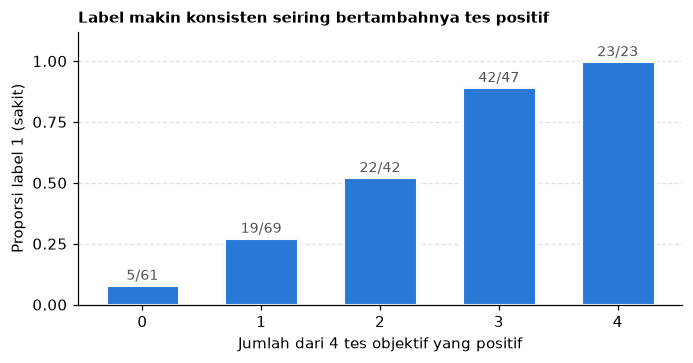

In [13]:
ev["t_ca"]    = (ev.ca >= 1).astype(int)            # >= 1 pembuluh terlihat pada fluoroskopi
ev["t_thal"]  = ev.thal.isin([6, 7]).astype(int)    # defek pada tes thallium
ev["t_exang"] = (ev.exang == 1).astype(int)         # angina saat latihan
ev["t_st"]    = (ev.oldpeak >= 1).astype(int)       # depresi ST >= 1 mm
ev["n_tes"]   = ev[["t_ca", "t_thal", "t_exang", "t_st"]].sum(axis=1)
ev["imputasi"] = ev[["ca", "thal"]].isna().any(axis=1)

base_rate = ev.groupby("n_tes").y.agg(jumlah="count", sakit="sum", proporsi_sakit="mean").round(3)
base_rate["ditandai_cleanlab"] = ev[ev.flag].groupby("n_tes").size().reindex(base_rate.index, fill_value=0)
display(base_rate)
print("Pasien ca = 3 di train:", ev[ev.ca == 3].y.value_counts().sort_index().to_dict())

fig, ax = plt.subplots(figsize=(6.4, 3.4))
xs = base_rate.index.to_numpy()
bars = ax.bar(xs, base_rate.proporsi_sakit, width=.62, color="#2a78d6", edgecolor="#fcfcfb", linewidth=2)
for x, r in zip(xs, base_rate.itertuples()):
    ax.text(x, r.proporsi_sakit + .02, f"{r.sakit}/{r.jumlah}", ha="center", fontsize=9, color="#52514e")
ax.set_xticks(xs); ax.set_ylim(0, 1.12); ax.set_yticks([0, .25, .5, .75, 1])
ax.set_xlabel("Jumlah dari 4 tes objektif yang positif")
ax.set_ylabel("Proporsi label 1 (sakit)")
ax.set_title("Label makin konsisten seiring bertambahnya tes positif", fontsize=10, fontweight="bold", loc="left")
ax.grid(axis="y", linestyle="--", alpha=.35); ax.set_axisbelow(True)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/label_vs_tes_objektif.png", bbox_inches="tight"); plt.show()

**Cara membaca:** label dan hasil tes sangat konsisten. Dengan 3 tes positif, 42 dari 47 pasien (89%) berlabel sakit; dengan 4 tes positif, 23 dari 23. Sebaliknya, dengan 0 tes positif hanya 5 dari 61 (8%) yang berlabel sakit, dan **kelima pasien itu semuanya ditandai Cleanlab**.

Dua kondisi ini **tidak simetris**, dan perbedaan ini menjadi dasar aturan di C4:
- **Label 1 dengan 0 tes positif** tidak membantah label. Tes-tes ini tidak sempurna, dan angiografi menemukan penyempitan secara langsung. Target juga hasil binarisasi `num` 1–4 → 1, sehingga penyakit ringan bisa saja tanpa tanda. Mengubah label ini berarti mengajari model bahwa pasien sakit itu sehat, yaitu kesalahan yang paling mahal (FN).
- **Label 0 dengan banyak tes positif** adalah pertentangan yang lebih nyata, karena beberapa temuan terukur harus salah sekaligus agar label itu benar. `ca` = 3 paling menonjol: hanya 1 dari 12 pasien seperti itu berlabel sehat.

## C3. Apakah ketidakcocokan berasal dari imputasi?

Satu kandidat, `row_id` 266, tidak punya nilai `thal`, salah satu fitur terkuat menurut SHAP Anggota 4. Imputasi modus mengisinya dengan 3 (normal). Kalau keputusan model berubah mengikuti nilai imputasi, ketidakcocokannya berasal dari data yang kosong, bukan dari labelnya. Sel di bawah mencoba ketiga nilai `thal` pada Random Forest di fold tempat pasien ini berada di validasi.

In [14]:
r266 = train_df[train_df.row_id == 266].copy()
hasil = []
for k, (tr_ids, va_ids, rep) in enumerate(cv):
    if 266 not in va_ids:
        continue
    tr = by_id.loc[tr_ids].reset_index(drop=True)
    for nilai in [3, 6, 7]:
        v = r266.copy(); v["thal"] = float(nilai)
        X_tr, y_tr, X_ev, _ = preprocess_E5(tr.drop(columns=["row_id"]), v.drop(columns=["row_id", TARGET]))
        p = RandomForestClassifier(random_state=SEED, **RF_PARAMS).fit(X_tr, y_tr).predict_proba(X_ev)[0, 1]
        hasil.append({"repeat": rep, "thal": nilai, "p_rf": p})
display(r266[["row_id", "age", "sex", "cp", "exang", "oldpeak", "slope", "ca", "thal", TARGET]])
display(pd.DataFrame(hasil).groupby("thal").p_rf.mean().round(3).rename("p_rf rata-rata 3 repeat").to_frame())

,row_id,age,sex,cp,exang,oldpeak,slope,ca,thal,num
219,266,52.0,1.0,4.0,1.0,1.0,2.0,0.0,NaN,1


,p_rf rata-rata 3 repeat
thal,
3,0.344
6,0.522
7,0.761


**Cara membaca:** probabilitas sakit bergerak dari 0,344 (`thal` = 3, hasil imputasi) ke 0,522 (`thal` = 6) dan 0,761 (`thal` = 7). Jadi model menentang label ini **hanya karena nilai yang diisi otomatis**. Pasien ini juga punya angina saat latihan dan depresi ST 1,0 mm, yang mendukung label sakit. Tidak ada alasan untuk mencurigai labelnya, sehingga keputusannya **Keep**.

## C4. Aturan keputusan dan tabel review

Aturan ditulis sebelum D2/D3 dijalankan, jadi tidak dipilih berdasarkan skor CV. Ambang `kualitas` < 0,2 sama dengan yang dipakai Anggota 4. Sebuah kandidat disebut **konsisten** bila memenuhi semuanya: `kualitas` < 0,2, salah di 3 dari 3 repeat, RF dan CNN sama-sama menentang label, dan 3 dari 3 model pembanding juga menentang.

| Keputusan | Syarat | Efek pada D2/D3 |
|---|---|---|
| **Correct** | label 0, konsisten, dan bertentangan kuat dengan tes objektif (≥ 3 tes positif, atau `ca` = 3) | label diubah di train fold |
| **Remove** | record tidak valid: duplikat, nilai mustahil, atau tidak bisa dinilai sama sekali | baris dibuang dari train fold |
| **Unresolved** | konsisten, tetapi tidak ada bukti yang membantah label: label 0 dengan tes kurang kuat, atau label 1 dengan 0 tes positif | tidak diubah |
| **Keep** | selain itu: ada tes yang mendukung label, ketidakcocokan tidak konsisten, atau berasal dari imputasi | tidak diubah |

Koreksi 1 → 0 sengaja tidak diizinkan, dengan alasan di C2.

In [15]:
def keputusan(r):
    """Aturan berurutan; ambang ditetapkan sebelum D2/D3 dijalankan."""
    konsisten = (r.kualitas < .2) and r.salah_n_repeat == 3 and r.rf_cnn_menentang and r.alt_menentang == 3
    if r.imputasi:
        return "Keep", "fitur kunci diimputasi; ketidakcocokan dapat berasal dari imputasi (C3)"
    if r.y == 0:
        if konsisten and (r.n_tes >= 3 or r.ca == 3):
            return "Correct", f"semua model menentang, dan label 0 bertentangan dengan tes objektif ({r.n_tes}/4 positif, ca={r.ca:.0f})"
        if konsisten:
            return "Unresolved", f"semua model menentang, tetapi hanya {r.n_tes}/4 tes positif; bisa positif palsu tes"
        return "Keep", "pertentangan tidak konsisten; kasus perbatasan"
    if konsisten and r.n_tes == 0:
        return "Unresolved", "profil sepenuhnya negatif, tetapi tes negatif tidak membantah temuan angiografi"
    return "Keep", (f"{r.n_tes}/4 tes positif mendukung label" if r.n_tes else "pertentangan tidak konsisten antar-model")


review = ev[ev.flag].sort_values("kualitas").copy()
review[["keputusan", "alasan"]] = review.apply(lambda r: pd.Series(keputusan(r)), axis=1)
sp = pd.read_csv(f"{ART_DIR}/anggota4/salah_prediksi.csv")[["row_id", "indikasi"]]
review = review.merge(sp, on="row_id", how="left").rename(columns={"indikasi": "indikasi_anggota4"})
review["label_baru"] = np.where(review.keputusan == "Correct", 1 - review.y, np.nan)

kolom = ["row_id", "y", "prob", "kualitas", "flag_n_repeat", "salah_n_repeat", "rf_cnn_menentang", "alt_menentang", "n_tes",
         "age", "sex", "cp", "ca", "thal", "exang", "oldpeak", "keputusan", "label_baru", "alasan", "indikasi_anggota4"]
review[kolom].round(3).to_csv(f"{OUT_DIR}/keputusan_label.csv", index=False)
print("Rekap keputusan:", review.keputusan.value_counts().to_dict())
print("Irisan dengan 13 pasien 'label?' Anggota 4:",
      int(review.indikasi_anggota4.fillna("").str.startswith("label?").sum()))
with pd.option_context("display.max_colwidth", None):
    display(review[kolom[:9] + ["keputusan", "alasan"]].round(3))

Rekap keputusan: {'Keep': 18, 'Unresolved': 6, 'Correct': 2}
Irisan dengan 13 pasien 'label?' Anggota 4: 12


,row_id,y,prob,kualitas,flag_n_repeat,salah_n_repeat,rf_cnn_menentang,alt_menentang,n_tes,keputusan,alasan
0,145,1,0.048,0.048,3,3,True,3,0,Unresolved,"profil sepenuhnya negatif, tetapi tes negatif tidak membantah temuan angiografi"
1,252,0,0.934,0.066,3,3,True,3,3,Correct,"semua model menentang, dan label 0 bertentangan dengan tes objektif (3/4 positif, ca=1)"
2,32,1,0.081,0.081,3,3,True,3,0,Unresolved,"profil sepenuhnya negatif, tetapi tes negatif tidak membantah temuan angiografi"
3,22,1,0.130,0.130,3,3,True,3,1,Keep,1/4 tes positif mendukung label
4,261,1,0.147,0.147,3,3,True,3,1,Keep,1/4 tes positif mendukung label
5,199,1,0.151,0.151,3,3,True,3,0,Unresolved,"profil sepenuhnya negatif, tetapi tes negatif tidak membantah temuan angiografi"
6,171,0,0.839,0.161,3,3,True,3,2,Unresolved,"semua model menentang, tetapi hanya 2/4 tes positif; bisa positif palsu tes"
7,176,0,0.834,0.166,3,3,True,3,2,Correct,"semua model menentang, dan label 0 bertentangan dengan tes objektif (2/4 positif, ca=3)"
8,301,1,0.171,0.171,3,3,True,3,1,Keep,1/4 tes positif mendukung label
9,274,1,0.171,0.171,3,3,True,3,1,Keep,1/4 tes positif mendukung label


### Tabel keputusan

| Keputusan | Jumlah | `row_id` | Alasan ringkas |
|---|---:|---|---|
| **Correct** (0 → 1) | 2 | 252, 176 | Semua model menentang label di semua repeat. 252: 3 dari 4 tes positif (`ca`=1, `thal`=7, angina saat latihan), hanya 5 dari 70 pasien dengan ≥ 3 tes positif berlabel sehat. 176: `ca`=3 dan `thal`=7, satu-satunya dari 12 pasien `ca`=3 yang berlabel sehat |
| **Remove** | 0 | — | Tidak ada record yang tidak valid: duplikat persis 0, dan satu record tidak lengkap (266) masih bisa dinilai |
| **Unresolved** | 6 | 145, 32, 199, 44, 184, 171 | Lima pertama: label 1, ke-4 tes negatif, tetapi tes negatif tidak membantah angiografi. 171: label 0, `thal`=7 dan angina saat latihan, tetapi hanya 2 tes positif dan `ca`=0, sehingga bisa jadi positif palsu tes |
| **Keep** | 18 | 22, 261, 301, 274, 294, 214, 278, 124, 232, 209, 259 | Label 1 dengan ≥ 1 tes positif yang mendukung label (mis. 232 dan 261 punya `ca` ≥ 2). Model yang keliru, bukan labelnya |
| | | 266 | Ketidakcocokan berasal dari imputasi `thal` (C3) |
| | | 183, 218, 80, 165, 275, 130 | Label 0, `kualitas` ≥ 0,26, kasus perbatasan yang tidak konsisten |

Tabel per pasien lengkap tersimpan di `artifacts/anggota3/keputusan_label.csv`.

**Catatan penting:**
- Dua koreksi ini adalah **keputusan terbaik dari bukti tidak langsung**, bukan hasil verifikasi rekam medis. Keduanya bisa ditinjau ulang bila data asli `num` 0–4 atau catatan klinis tersedia.
- Irisan dengan daftar `label?` Anggota 4 adalah 12 dari 13 pasien. Ini sudah diperkirakan, karena skornya sama, jadi bukan konfirmasi independen.
- Pasien label 0 dengan ≥ 3 tes positif sebenarnya ada 5, tetapi hanya 252 yang ditandai Cleanlab. Empat lainnya tidak direview, karena model tidak menentang labelnya.

In [16]:
# Dikunci sebagai keputusan manusia: tidak dihitung ulang otomatis, agar pergeseran kecil TF antar-mesin tidak mengubah dataset
LABEL_OVERRIDES = {252: 1, 176: 1}   # keputusan 'Correct'
DROP_IDS        = []                 # keputusan 'Remove': tidak ada

assert LABEL_OVERRIDES == {int(r.row_id): int(r.label_baru) for r in review[review.keputusan == "Correct"].itertuples()}
assert not set(LABEL_OVERRIDES) & set(test_df.row_id), "label test set tidak boleh diubah"
assert not set(DROP_IDS) & set(test_df.row_id)
print("Koreksi:", LABEL_OVERRIDES, "| Hapus:", DROP_IDS,
      f"| {len(LABEL_OVERRIDES) + len(DROP_IDS)} dari {len(train_df)} baris train berubah")

Koreksi: {252: 1, 176: 1} | Hapus: [] | 2 dari 242 baris train berubah


# BAGIAN D | Eksperimen D0–D3 (Instruksi 5)

## D1. Desain eksperimen

| Dataset | Label | Imbalance | `exp` | Sumber |
|---|---|---|---|---|
| **D0** | asli | — | `E5` | Anggota 1 |
| **D1** | asli | SMOTE | `D1_smote` | Anggota 2 |
| **D2** | terkoreksi | — | `D2` | notebook ini |
| **D3** | terkoreksi | SMOTE | `D3` | notebook ini |

Urutan pada D3 mengikuti soal: label dikoreksi lebih dulu, baru SMOTE, baru training. `evaluate_cv` sudah menjalankan urutan ini di setiap fold (`apply_train_modifications` → `preprocess_E5` → `resampler` → `fit_predict`). Model, fitur, dan fold tidak berubah, dan fold validasi selalu memuat semua barisnya.

D2 dan D3 ditulis ke `cv_results.csv` bersama. Varian label validasi terkoreksi dan rerun D0/D1 disimpan terpisah di `anggota3/cv_diagnostics.csv` agar berkas bersama tetap bersih. Rerun D0/D1 dipakai untuk mendapatkan probabilitas per fold.

In [17]:
smote = lambda X, y: SMOTE(random_state=SEED).fit_resample(X, y)
ens   = make_ensemble_fit_predict()
MAIN  = f"{ART_DIR}/cv_results.csv"
mods  = dict(label_overrides=LABEL_OVERRIDES, drop_ids=DROP_IDS or None)

# Label validasi asli (default): masuk ke cv_results.csv bersama
fold_d2, oof_d2 = run_or_load("D2", MAIN, f"{OUT_DIR}/oof_d2.csv", fit_predict=ens, **mods)
fold_d3, oof_d3 = run_or_load("D3", MAIN, f"{OUT_DIR}/oof_d3.csv", fit_predict=ens, resampler=smote, **mods)

# Label validasi terkoreksi (diagnostik): disimpan terpisah
fold_d2c, _ = run_or_load("D2_evalcorr", DIAG_CSV, f"{OUT_DIR}/oof_d2_evalcorr.csv", fit_predict=ens, eval_on_corrected=True, **mods)
fold_d3c, _ = run_or_load("D3_evalcorr", DIAG_CSV, f"{OUT_DIR}/oof_d3_evalcorr.csv", fit_predict=ens, resampler=smote, eval_on_corrected=True, **mods)

# D1 dijalankan ulang agar selisih berpasangan tidak tercampur perbedaan mesin, dan probabilitas per fold tersimpan untuk D4
perfold1_path, store1 = f"{OUT_DIR}/oof_d1_perfold.csv", []
fold_d1r, oof_d1r = run_or_load("D1_rerun", DIAG_CSV, f"{OUT_DIR}/oof_d1_rerun.csv",
                                fit_predict=recording(ens, store1), resampler=smote)
if store1:
    pd.concat([pd.DataFrame({"row_id": va, "fold": k, "repeat": rep, **store1[k]})
               for k, (_, va, rep) in enumerate(cv)]).to_csv(perfold1_path, index=False)

## D2. Tabel perbandingan D0–D3 (mean ± std 15 fold)

In [18]:
r_main = pd.read_csv(MAIN)
r_diag = pd.read_csv(DIAG_CSV)
nama_d0, nama_d1 = "D0: baseline (E5)", "D1: SMOTE"
sumber = {"D0: baseline (E5)":          r_diag[r_diag.exp == "D0_rerun"],
          "D1: SMOTE":                  r_diag[r_diag.exp == "D1_rerun"],
          "D2: koreksi label":          r_main[r_main.exp == "D2"],
          "D3: koreksi label + SMOTE":  r_main[r_main.exp == "D3"]}


def tabel(sumber):
    return pd.DataFrame({nama: {"n_train (mean)": f"{s.n_train.mean():.1f}",
                                **{m: f"{s[m].mean():.4f} ± {s[m].std():.4f}" for m in ALL_METRIC_COLS}}
                         for nama, s in sumber.items()})


t_d = tabel(sumber)
t_d.to_csv(f"{OUT_DIR}/d0_d3_summary_table.csv")
display(t_d)

# Rerun harus identik dengan angka yang dikunci anggota lain
for kode, s in [(BASELINE_CODE, sumber[nama_d0]), ("D1_smote", sumber[nama_d1])]:
    a, b = r_main[r_main.exp == kode].sort_values("fold").macro_f1.values, s.sort_values("fold").macro_f1.values
    print(f"{kode:9s} macro_f1 tersimpan {a.mean():.4f} | rerun {b.mean():.4f} | fold identik {int(np.isclose(a, b).sum())}/15")

,D0: baseline (E5),D1: SMOTE,D2: koreksi label,D3: koreksi label + SMOTE
n_train (mean),193.6,209.6,193.6,206.4
accuracy,0.8074 ± 0.0601,0.8169 ± 0.0553,0.8115 ± 0.0551,0.8115 ± 0.0604
macro_f1,0.8028 ± 0.0632,0.8120 ± 0.0587,0.8073 ± 0.0579,0.8069 ± 0.0632
balanced_acc,0.8021 ± 0.0616,0.8117 ± 0.0573,0.8066 ± 0.0568,0.8065 ± 0.0615
mcc,0.6161 ± 0.1196,0.6379 ± 0.1076,0.6240 ± 0.1096,0.6257 ± 0.1185
precision,0.8294 ± 0.0771,0.8451 ± 0.0743,0.8304 ± 0.0687,0.8356 ± 0.0801
recall,0.7360 ± 0.1046,0.7451 ± 0.1135,0.7452 ± 0.1010,0.7420 ± 0.1067
f1_pos,0.7756 ± 0.0779,0.7856 ± 0.0739,0.7815 ± 0.0717,0.7807 ± 0.0769
specificity,0.8683 ± 0.0718,0.8783 ± 0.0769,0.8681 ± 0.0647,0.8709 ± 0.0794
roc_auc,0.8903 ± 0.0478,0.8942 ± 0.0509,0.8937 ± 0.0453,0.8926 ± 0.0479


E5        macro_f1 tersimpan 0.8028 | rerun 0.8028 | fold identik 15/15
D1_smote  macro_f1 tersimpan 0.8120 | rerun 0.8120 | fold identik 15/15


**Cara membaca:** rerun D0 dan D1 identik dengan angka tersimpan di 15 dari 15 fold, jadi keempat kolom sebanding. Jumlah data train D3 (206,4) lebih kecil dari D1 (209,6) karena dua koreksi 0 → 1 memperkecil selisih kelas, sehingga SMOTE membuat lebih sedikit sampel sintetis.

Urutan macro F1: **D1 0,8120 > D2 0,8073 > D3 0,8069 > D0 0,8028**. Semua selisihnya jauh lebih kecil dari std antar-fold (±0,06), jadi yang perlu dilihat adalah selisih berpasangan di bawah.

## D3. Selisih berpasangan per fold

Ke-15 fold sama persis, jadi selisih per fold lebih tajam daripada membandingkan dua mean. Pasangan yang dibandingkan: tiap dataset terhadap D0, D3 terhadap D1 (efek koreksi pada kondisi SMOTE), dan D3 terhadap D2 (efek SMOTE pada label terkoreksi). Dua puluh lima uji pada 15 fold yang saling tumpang-tindih tidak independen, jadi nilai p di sini hanya penunjuk arah.

,Perbandingan,Metrik,Delta mean,Delta std,Menang / Kalah / Seri,p (paired t),p (Wilcoxon)
0,D1 − D0,macro_f1,+0.0092,0.0170,10 / 3 / 2,0.0539,0.1272
1,D1 − D0,balanced_acc,+0.0095,0.0168,10 / 3 / 2,0.0449,0.0608
2,D1 − D0,mcc,+0.0218,0.0369,9 / 4 / 2,0.0380,0.0398
3,D1 − D0,recall,+0.0091,0.0307,5 / 2 / 8,0.2711,0.1094
4,D1 − D0,specificity,+0.0100,0.0335,6 / 3 / 6,0.2684,0.3555
5,D2 − D0,macro_f1,+0.0045,0.0225,5 / 3 / 7,0.4517,0.3828
6,D2 − D0,balanced_acc,+0.0045,0.0222,5 / 3 / 7,0.4445,0.2656
7,D2 − D0,mcc,+0.0079,0.0457,5 / 3 / 7,0.5146,0.8438
8,D2 − D0,recall,+0.0092,0.0252,4 / 1 / 10,0.1780,0.1250
9,D2 − D0,specificity,-0.0002,0.0249,3 / 3 / 9,0.9768,0.7500


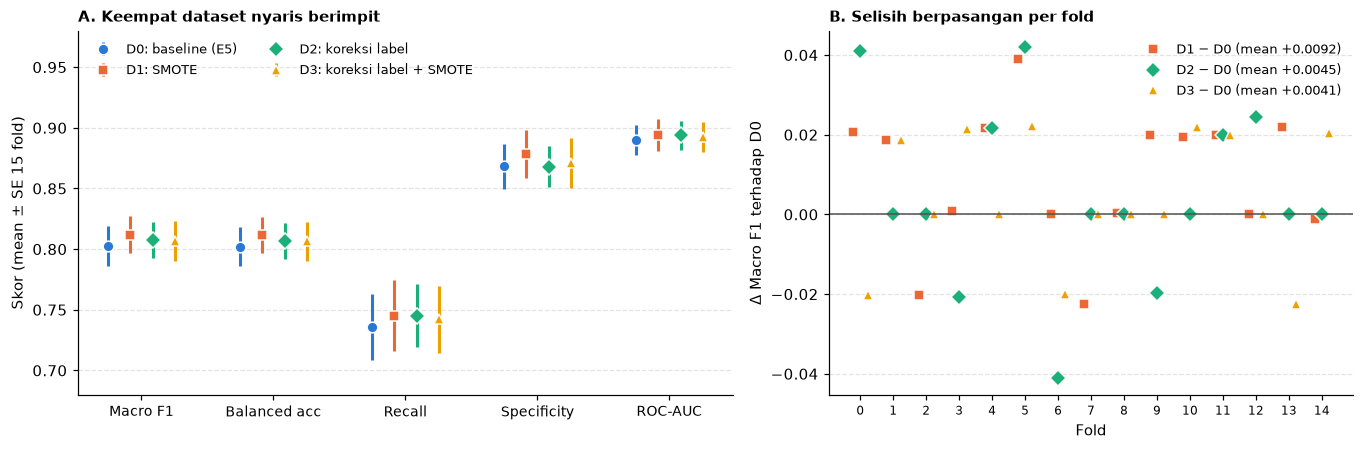

In [19]:
def paired(a, b, metrics=("macro_f1", "balanced_acc", "mcc", "recall", "specificity")):
    rows = []
    fa, fb = sumber[a].set_index("fold"), sumber[b].set_index("fold")
    for m in metrics:
        d = (fb[m] - fa[m]).sort_index()
        nz = d[d.abs() > 1e-9]
        rows.append({"Perbandingan": f"{b.split(':')[0]} − {a.split(':')[0]}", "Metrik": m,
                     "Delta mean": f"{d.mean():+.4f}", "Delta std": round(d.std(), 4),
                     "Menang / Kalah / Seri": f"{int((d > 1e-9).sum())} / {int((d < -1e-9).sum())} / {int((d.abs() <= 1e-9).sum())}",
                     "p (paired t)": round(ttest_rel(fb[m].sort_index(), fa[m].sort_index()).pvalue, 4),
                     "p (Wilcoxon)": round(wilcoxon(nz).pvalue, 4) if len(nz) else 1.0})
    return rows


nama = list(sumber)
paired_df = pd.DataFrame(paired(nama[0], nama[1]) + paired(nama[0], nama[2]) + paired(nama[0], nama[3]) +
                         paired(nama[1], nama[3]) + paired(nama[2], nama[3]))
paired_df.to_csv(f"{OUT_DIR}/d0_d3_paired_comparison.csv", index=False)
display(paired_df)

warna = dict(zip(nama, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]))
penanda = dict(zip(nama, ["o", "s", "D", "^"]))
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2), gridspec_kw={"width_ratios": [1.25, 1]})

metrik_plot = ["macro_f1", "balanced_acc", "recall", "specificity", "roc_auc"]
label_plot  = ["Macro F1", "Balanced acc", "Recall", "Specificity", "ROC-AUC"]
for i, n in enumerate(nama):
    s = sumber[n]
    x = np.arange(len(metrik_plot)) + (i - 1.5) * .17
    axes[0].errorbar(x, [s[m].mean() for m in metrik_plot],
                     yerr=[s[m].std() / np.sqrt(len(s)) for m in metrik_plot], fmt=penanda[n], ms=7, lw=2, capsize=0,
                     color=warna[n], mec="#fcfcfb", mew=1, label=n)
axes[0].set_xticks(np.arange(len(metrik_plot))); axes[0].set_xticklabels(label_plot, fontsize=9)
axes[0].set_ylabel("Skor (mean ± SE 15 fold)")
axes[0].set_title("A. Keempat dataset nyaris berimpit", fontsize=10, fontweight="bold", loc="left")
axes[0].legend(frameon=False, fontsize=8.5, loc="upper left", ncol=2); axes[0].set_ylim(.68, .98)
axes[0].grid(axis="y", linestyle="--", alpha=.35); axes[0].set_axisbelow(True)

base = sumber[nama[0]].set_index("fold").macro_f1.sort_index()
for n, off in zip(nama[1:], [-.22, 0, .22]):
    d = sumber[n].set_index("fold").macro_f1.sort_index() - base
    axes[1].plot(d.index + off, d.values, penanda[n], ms=7, color=warna[n], mec="#fcfcfb", mew=1,
                 label=f"{n.split(':')[0]} − D0 (mean {d.mean():+.4f})")
axes[1].axhline(0, color="#52514e", lw=1)
axes[1].set_xticks(range(15)); axes[1].tick_params(axis="x", labelsize=8)
axes[1].set_xlabel("Fold"); axes[1].set_ylabel("Δ Macro F1 terhadap D0")
axes[1].set_title("B. Selisih berpasangan per fold", fontsize=10, fontweight="bold", loc="left")
axes[1].legend(frameon=False, fontsize=8.5); axes[1].grid(axis="y", linestyle="--", alpha=.35); axes[1].set_axisbelow(True)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/d0_d3_comparison.png", bbox_inches="tight"); plt.show()

**Cara membaca:**
- **D2 − D0:** macro F1 +0,0045 ± 0,0225; menang 5, kalah 3, seri 7; p = 0,45. Kenaikan terbesar ada pada recall (+0,0092), tetapi juga tidak signifikan (p = 0,18). Tidak ada bukti koreksi label memperbaiki model.
- **D3 − D0:** macro F1 +0,0041; menang 6, kalah 3, seri 6; p = 0,34.
- **D3 − D1:** macro F1 −0,0051; menang 5, kalah 7, seri 3; p = 0,38. Menambahkan koreksi label pada SMOTE tidak membantu, dan arahnya justru sedikit turun.
- **D3 − D2:** macro F1 −0,0004; p = 0,96. Pada label terkoreksi, SMOTE tidak lagi memberi manfaat yang terlihat.
- **D1 − D0** tetap satu-satunya perbandingan yang mendekati signifikan (MCC p = 0,038, balanced accuracy p = 0,045, sama dengan temuan Anggota 2). Dengan 25 uji pada fold yang saling tumpang-tindih, angka ini pun perlu dibaca hati-hati.

Hasil ini masuk akal: hanya 2 dari 242 baris (0,8%) yang berubah, jadi efeknya memang tidak bisa besar. Perubahan per fold kemungkinan lebih mencerminkan guncangan kecil pada proses training daripada perbaikan yang sistematis.

## D4. Evaluasi pada label validasi terkoreksi (`eval_on_corrected=True`)

Label validasi asli (D2, D3 di atas) akan menghukum model bila koreksinya benar. Sebaliknya, label validasi terkoreksi menguntungkan koreksi secara otomatis, karena baris yang model sebut sakit kini memang berlabel sakit. Sesuai aturan kerangka, keduanya dilaporkan sebagai batas bawah dan batas atas.

In [20]:
def skor_terkoreksi(perfold_csv):
    """Skor ulang model tanpa koreksi pada label validasi terkoreksi, agar sebanding dengan D2/D3 di kolom yang sama."""
    pf, rows = pd.read_csv(perfold_csv), []
    y_cor = train_df.set_index("row_id")[TARGET].to_dict() | LABEL_OVERRIDES
    for k, g in pf.groupby("fold"):
        y = g.row_id.map(y_cor).to_numpy(int)
        rows.append({"fold": k, "n_train": np.nan, **compute_metrics(y, (g.prob >= .5).astype(int), g.prob)})
    return pd.DataFrame(rows)


d0c, d1c = skor_terkoreksi(perfold_path), skor_terkoreksi(perfold1_path)
t_c = tabel({"D0": sumber[nama[0]], "D1": sumber[nama[1]], "D2": sumber[nama[2]], "D3": sumber[nama[3]],
             "D0 (terkoreksi)": d0c, "D1 (terkoreksi)": d1c,
             "D2 (terkoreksi)": r_diag[r_diag.exp == "D2_evalcorr"], "D3 (terkoreksi)": r_diag[r_diag.exp == "D3_evalcorr"]})
t_c.to_csv(f"{OUT_DIR}/d2_d3_eval_asli_vs_terkoreksi.csv")
display(t_c.loc[["macro_f1", "balanced_acc", "mcc", "recall", "specificity"]])

# Nasib pasien yang dikoreksi: prediksi OOF saat label mereka sendiri berada di validasi
ids = list(LABEL_OVERRIDES)
nasib = oof_d0r[oof_d0r.row_id.isin(ids)][["row_id", "prob"]].rename(columns={"prob": "prob_d0"})
nasib = nasib.merge(oof_d2[["row_id", "prob"]].rename(columns={"prob": "prob_d2"}), on="row_id")
nasib = nasib.merge(oof_d3[["row_id", "prob"]].rename(columns={"prob": "prob_d3"}), on="row_id")
display(nasib.round(3))

# Perubahan prediksi OOF pada seluruh pasien train
pred = lambda o: o.sort_values("row_id").set_index("row_id").prob.ge(.5).astype(int)
p0, p2, p3 = pred(oof_d0r), pred(oof_d2), pred(oof_d3)
print("Pasien yang berubah prediksi, D2 vs D0:", p0.index[p0 != p2].tolist(), "| D3 vs D0:", p0.index[p0 != p3].tolist())
for nm, o in [("D0", oof_d0r), ("D2", oof_d2), ("D3", oof_d3)]:
    y0 = oof_d0.set_index("row_id").y.reindex(o.row_id).values
    tn, fp, fn, tp = confusion_matrix(y0, (o.prob >= .5).astype(int), labels=[0, 1]).ravel()
    print(f"  {nm}: TN={tn} FP={fp} FN={fn} TP={tp} (OOF, terhadap label asli)")

,D0,D1,D2,D3,D0 (terkoreksi),D1 (terkoreksi),D2 (terkoreksi),D3 (terkoreksi)
macro_f1,0.8028 ± 0.0632,0.8120 ± 0.0587,0.8073 ± 0.0579,0.8069 ± 0.0632,0.8113 ± 0.0630,0.8205 ± 0.0588,0.8158 ± 0.0576,0.8154 ± 0.0626
balanced_acc,0.8021 ± 0.0616,0.8117 ± 0.0573,0.8066 ± 0.0568,0.8065 ± 0.0615,0.8103 ± 0.0617,0.8198 ± 0.0577,0.8147 ± 0.0566,0.8146 ± 0.0613
mcc,0.6161 ± 0.1196,0.6379 ± 0.1076,0.6240 ± 0.1096,0.6257 ± 0.1185,0.6332 ± 0.1182,0.6549 ± 0.1065,0.6409 ± 0.1076,0.6425 ± 0.1162
recall,0.7360 ± 0.1046,0.7451 ± 0.1135,0.7452 ± 0.1010,0.7420 ± 0.1067,0.7396 ± 0.1061,0.7484 ± 0.1150,0.7487 ± 0.1023,0.7455 ± 0.1083
specificity,0.8683 ± 0.0718,0.8783 ± 0.0769,0.8681 ± 0.0647,0.8709 ± 0.0794,0.8810 ± 0.0616,0.8911 ± 0.0672,0.8808 ± 0.0528,0.8836 ± 0.0690


,row_id,prob_d0,prob_d2,prob_d3
0,176,0.834,0.848,0.876
1,252,0.934,0.942,0.945


Pasien yang berubah prediksi, D2 vs D0: [246] | D3 vs D0: [12, 57, 246]
  D0: TN=115 FP=16 FN=30 TP=81 (OOF, terhadap label asli)
  D2: TN=115 FP=16 FN=29 TP=82 (OOF, terhadap label asli)
  D3: TN=115 FP=16 FN=29 TP=82 (OOF, terhadap label asli)


**Cara membaca:**
- **Mengganti label validasi menaikkan semua kolom dengan jumlah yang hampir sama** (macro F1 sekitar +0,0085). Ini efek penilaian, bukan efek training: model memang sudah memprediksi 176 dan 252 sebagai sakit, dan kini prediksi itu dihitung benar.
- **Urutan tidak berubah pada label terkoreksi:** D1 0,8205 > D2 0,8158 > D3 0,8154 > D0 0,8113. Jadi hasil ini tidak bergantung pada label mana yang dipakai untuk menilai. Membandingkan D2 terkoreksi (0,8158) dengan D0 asli (0,8028) akan membesar-besarkan manfaat koreksi hampir tiga kali lipat (+0,0130 dibanding +0,0045).
- **Pasien yang dikoreksi:** probabilitasnya sudah tinggi pada D0 (0,834 dan 0,934) dan hanya naik sedikit. Koreksi tidak memberi model informasi baru tentang pasien ini.
- **Tingkat pasien:** pada D2 hanya satu prediksi OOF yang berubah (`row_id` 246, dari FN ke TP), pasien yang probabilitasnya memang sudah di sekitar ambang 0,5 pada analisis Anggota 2. Dari 30 FN, tersisa 29, dan FP tetap 16.

# BAGIAN E | Rekomendasi (Instruksi 5)

**Rekomendasi Anggota 3: dataset final = D1 (SMOTE, tanpa koreksi label).**

1. D1 tertinggi pada label validasi asli maupun terkoreksi, dan satu-satunya yang mendekati signifikan terhadap D0.
2. D2 dan D3 tidak terbukti lebih baik, sementara keduanya menanggung risiko tambahan: mengubah label tanpa verifikasi sumber. Tanpa manfaat yang terukur, risiko itu tidak sepadan.
3. Tidak memakai koreksi label adalah hasil yang sah: review tetap menjawab label mana yang patut dicurigai, dan eksperimen menunjukkan koreksinya tidak memberi manfaat terukur.

Selisih D1 terhadap D2/D3 sendiri tidak signifikan (D3 − D1: p = 0,38), jadi ini pilihan berdasarkan kehati-hatian, bukan bukti bahwa koreksi merugikan. Keputusan akhir tetap keputusan tim. Konfigurasinya di bawah ini; konfigurasi D2/D3 tetap tersedia bila tim memilih berbeda.

In [21]:
REKOMENDASI_DATASET_FINAL = {"kode": "D1", "label_overrides": None, "drop_ids": None, "resampler": smote}
KONFIGURASI_D2 = {"label_overrides": LABEL_OVERRIDES, "drop_ids": None, "resampler": None}
KONFIGURASI_D3 = {"label_overrides": LABEL_OVERRIDES, "drop_ids": None, "resampler": smote}

print("Rekomendasi Anggota 3:", REKOMENDASI_DATASET_FINAL["kode"], "(SMOTE, label asli)")
print("Bila tim memilih D2/D3, label_overrides =", LABEL_OVERRIDES)
print("Artefak di", OUT_DIR)
for fname in sorted(os.listdir(OUT_DIR)):
    print(" -", fname)

# --- TEMPLATE UNTUK ANGGOTA 4 (sel A10, FINAL) DAN EVALUASI TEST (ANGGOTA 1 + 2, INSTRUKSI 8) ---
# JANGAN dijalankan sebelum keputusan final dikunci bersama.
# m_final = final_test_eval("D_final", train_df, test_df, PREPROCESS[BASELINE_CODE],
#                           label_overrides=REKOMENDASI_DATASET_FINAL["label_overrides"],
#                           drop_ids=REKOMENDASI_DATASET_FINAL["drop_ids"],
#                           resampler=REKOMENDASI_DATASET_FINAL["resampler"])

Rekomendasi Anggota 3: D1 (SMOTE, label asli)
Bila tim memilih D2/D3, label_overrides = {252: 1, 176: 1}
Artefak di ./artifacts/anggota3
 - cv_diagnostics.csv
 - d0_d3_comparison.png
 - d0_d3_paired_comparison.csv
 - d0_d3_summary_table.csv
 - d2_d3_eval_asli_vs_terkoreksi.csv
 - keputusan_label.csv
 - label_vs_tes_objektif.png
 - oof_d0_perfold.csv
 - oof_d0_rerun.csv
 - oof_d1_perfold.csv
 - oof_d1_rerun.csv
 - oof_d2.csv
 - oof_d2_evalcorr.csv
 - oof_d3.csv
 - oof_d3_evalcorr.csv


# BAGIAN F | Bahan diskusi laporan (Instruksi 9, bagian Anggota 3)

### 1. Masalah kualitas data yang diidentifikasi
Label belum pernah diperiksa di Assignment #2 dan #3. Cleanlab menandai 26 dari 242 observasi train (10,7%), 16 di antaranya stabil di ketiga repeat. Sebagian besar (17 dari 26) berlabel sakit tetapi tampak sehat dari fiturnya, yang menjelaskan kenapa FN sulit diturunkan oleh penanganan imbalance (Anggota 2) dan selaras dengan temuan FN yang mirip TN (Anggota 4).

### 2. Intervensi yang dilakukan
Setiap kandidat direview dengan model pembanding, 4 tes objektif, dan pemeriksaan imputasi, memakai aturan yang ditulis sebelum eksperimen. Hasilnya **2 Correct, 0 Remove, 6 Unresolved, 18 Keep**. Koreksi hanya berlaku pada bagian train tiap fold, dan test set tidak diubah.

### 3. Dampak pada performa
| Dataset | Macro F1 (validasi asli) | Macro F1 (validasi terkoreksi) | Δ macro F1 vs D0 (validasi asli) |
|---|---|---|---|
| D0 | 0,8028 ± 0,0632 | 0,8113 ± 0,0630 | — |
| D1 | 0,8120 ± 0,0587 | 0,8205 ± 0,0588 | +0,0092 (p = 0,054) |
| D2 | 0,8073 ± 0,0579 | 0,8158 ± 0,0576 | +0,0045 (p = 0,45) |
| D3 | 0,8069 ± 0,0632 | 0,8154 ± 0,0626 | +0,0041 (p = 0,34) |

Koreksi label tidak meningkatkan performa secara berarti. Temuan utamanya justru bahwa **sebagian besar kandidat Cleanlab bukan label yang terbukti salah**: 18 dari 26 punya alasan untuk dipertahankan.

### 4. Limitasi
1. **Tidak ada ground truth.** Dataset hanya memuat target biner, tanpa nilai asli `num` 0–4 atau rekam medis, jadi tidak ada koreksi yang terverifikasi. Pasien Unresolved tetap tidak terjawab.
2. **Bukti tambahan tidak independen dari model.** Tes objektif adalah fitur yang juga dipakai model, sehingga aturan ini bisa memperkuat pola yang sudah dipelajari model.
3. **Ambang aturan adalah pilihan.** Aturan ditulis sebelum D2/D3, tetapi setelah melihat daftar Cleanlab dan hubungan tes dengan label di train. Ambang berbeda (mis. 2 tes positif) akan menghasilkan koreksi yang berbeda, misalnya `row_id` 171.
4. **Hasil CV D2/D3 cenderung optimistis.** Kandidat dipilih dari OOF seluruh data train, lalu dinilai pada fold yang sama, sehingga ada kebocoran informasi tidak langsung. Angka paling jujur ada di evaluasi test akhir.
5. **Efek terlalu kecil untuk diukur.** Dua baris dari 242, dengan fold validasi ±48 pasien (satu pasien ≈ 2% akurasi), tidak cukup untuk membedakan manfaat dari noise.
6. **Kemungkinan leakage `ca`** yang dicatat Anggota 4 juga berlaku di sini: bila `ca` berasal dari prosedur yang sama dengan label, kekuatan buktinya untuk `row_id` 176 perlu dibaca ulang.

### 5. Risiko keputusan cleaning
- **Menghapus atau membalik kasus sulit** membuat skor tampak lebih baik tanpa model menjadi lebih baik. Risiko ini terbesar pada 17 pasien sakit yang tampak sehat: mereka justru pasien yang paling berbahaya bila terlewat. Karena itu tidak ada koreksi 1 → 0 dan tidak ada penghapusan.
- **Koreksi 0 → 1** berisiko melabeli pasien sehat dengan hasil tes positif palsu sebagai sakit. Risikonya kecil karena hanya 2 pasien, tetapi tetap salah satu alasan D1 direkomendasikan.
- **Membaca label terkoreksi tanpa pembanding** dapat melebih-lebihkan manfaat koreksi. D0 dan D1 harus dinilai pada label yang sama (D4).

## Reproduksi
1. Pastikan `./artifacts/split.json`, `cv_splits.json`, `oof_baseline.csv`, dan `anggota4/salah_prediksi.csv` tersedia.
2. `pip install cleanlab imbalanced-learn` (versi yang dipakai tercetak di sel A9).
3. `Run All`. Dengan `FORCE_RERUN = False`, hasil dimuat dari `./artifacts/`.